In [1]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import yfinance as yf
import os

In [7]:
# --- 1. Definir los Tickers y el Rango de Fechas ---
# Esta es la lista de los 30 tickers que se usaron en tu guía
tickers = [
    'MMM', 'AXP', 'AAPL', 'BA', 'CAT', 'CVX', 'CSCO', 'KO', 'DIS',
    'XOM', 'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'MCD', 'MRK', 'MSFT',
    'NKE', 'PFE', 'PG', 'TRV', 'UNH', 'VZ', 'V', 'WMT', 'NVDA'
]

In [8]:
# Rango de fechas basado en tu documento (de 2000-01-03 a 2019-02-06)
# Pedimos un día más en la fecha final para asegurar que incluya el último día.
start_date = '2000-01-03'
end_date = '2025-10-20'

In [9]:
print(f"Descargando datos para {len(tickers)} tickers...")

# 1. Intenta descargar TODOS los datos (sin seleccionar 'Adj Close' aún)
try:
    full_data = yf.download(tickers, start=start_date, end=end_date)

    # 2. Revisa si la descarga está vacía
    if full_data.empty:
        print("\n--- ERROR ---")
        print("La descarga falló. yfinance devolvió una tabla vacía.")
        print("Revisa tu conexión o intenta descargar un solo ticker (ej. 'AAPL') para aislar el problema.")
    
    else:
        print("\nDescarga completa. Extrayendo 'Adj Close'...")
        
        # 3. Si no está vacía, AHORA SÍ selecciona 'Adj Close'
        # Usamos .get() para más seguridad, aunque ['Adj Close'] debería funcionar
        data = full_data.get('Close')
        
        if data is None:
            print("Error: No se encontró la columna 'Adj Close' en los datos descargados.")
            print("Datos descargados:")
            print(full_data.head())
        else:
            # 4. Guardar el archivo (sólo si todo salió bien)
            output_dir = 'inputs'
            file_path = os.path.join(output_dir, 'djia_adjusted_closes.csv')

            if not os.path.exists(output_dir):
                os.makedirs(output_dir)

            data.to_csv(file_path)
            print(f"\n¡Éxito! Datos guardados en: {file_path}")
            
            print("\nVerificación:")
            print(data.head())

except Exception as e:
    print(f"\nOcurrió un error inesperado durante la descarga: {e}")

Descargando datos para 28 tickers...


C:\Users\magal\AppData\Local\Temp\ipykernel_40140\429222304.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  full_data = yf.download(tickers, start=start_date, end=end_date)
[*********************100%***********************]  28 of 28 completed


Descarga completa. Extrayendo 'Adj Close'...

¡Éxito! Datos guardados en: inputs\djia_adjusted_closes.csv

Verificación:
Ticker          AAPL        AXP         BA        CAT       CSCO        CVX  \
Date                                                                          
2000-01-03  0.838496  32.150299  25.940290  12.520860  34.772568  15.721489   
2000-01-04  0.767802  30.936365  25.899940  12.359921  32.821766  15.721489   
2000-01-05  0.779038  30.150606  27.513639  12.649606  32.721214  16.003487   
2000-01-06  0.711621  30.764872  27.796045  13.293350  32.178207  16.684988   
2000-01-07  0.745330  31.212778  28.602886  13.727880  34.068672  16.978739   

Ticker            DIS         GS         HD        IBM  ...       NKE  \
Date                                                    ...             
2000-01-03  22.583420  61.038265  37.666798  57.088104  ...  4.441892   
2000-01-04  23.906309  57.193626  35.680523  55.150318  ...  4.199605   
2000-01-05  24.898462  54.515408

In [11]:
# --- 4. Verificar (Opcional) ---
# Leemos el archivo que acabamos de guardar para verificar
import pandas as pd

df_verificacion = pd.read_csv(file_path, index_col=0, parse_dates=True)
print("\nVerificación (primeras 5 filas del archivo guardado):")

df_verificacion.head()


Verificación (primeras 5 filas del archivo guardado):


,AAPL,AXP,BA,CAT,CSCO,CVX,DIS,GS,HD,IBM,...,NKE,NVDA,PFE,PG,TRV,UNH,V,VZ,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-03,0.838496,32.150299,25.940290,12.520860,34.772568,15.721489,22.583420,61.038265,37.666798,57.088104,...,4.441892,0.089410,11.458942,26.633139,17.324270,5.169806,NaN,15.084000,14.181556,17.141260
2000-01-04,0.767802,30.936365,25.899940,12.359921,32.821766,15.721489,23.906309,57.193626,35.680523,55.150318,...,4.199605,0.087023,11.032045,26.120665,17.094597,5.103680,NaN,14.596413,13.650902,16.812952
2000-01-05,0.779038,30.150606,27.513639,12.649606,32.721214,16.003487,24.898462,54.515408,36.402817,57.088104,...,4.441892,0.084158,11.211789,25.623728,16.963348,5.091658,NaN,15.084000,13.372311,17.729521
2000-01-06,0.711621,30.764872,27.796045,13.293350,32.178207,16.684988,23.906309,56.848068,34.669373,56.103825,...,4.418818,0.078667,11.616222,26.803972,17.291468,5.278009,NaN,15.007375,13.518253,18.646091
2000-01-07,0.745330,31.212778,28.602886,13.727880,34.068672,16.978739,23.528339,57.064045,36.691719,55.857792,...,4.418818,0.079980,12.402622,28.947058,17.980497,5.897184,NaN,14.896568,14.539736,18.591368


Datos cargados exitosamente.
Matriz de correlación calculada.


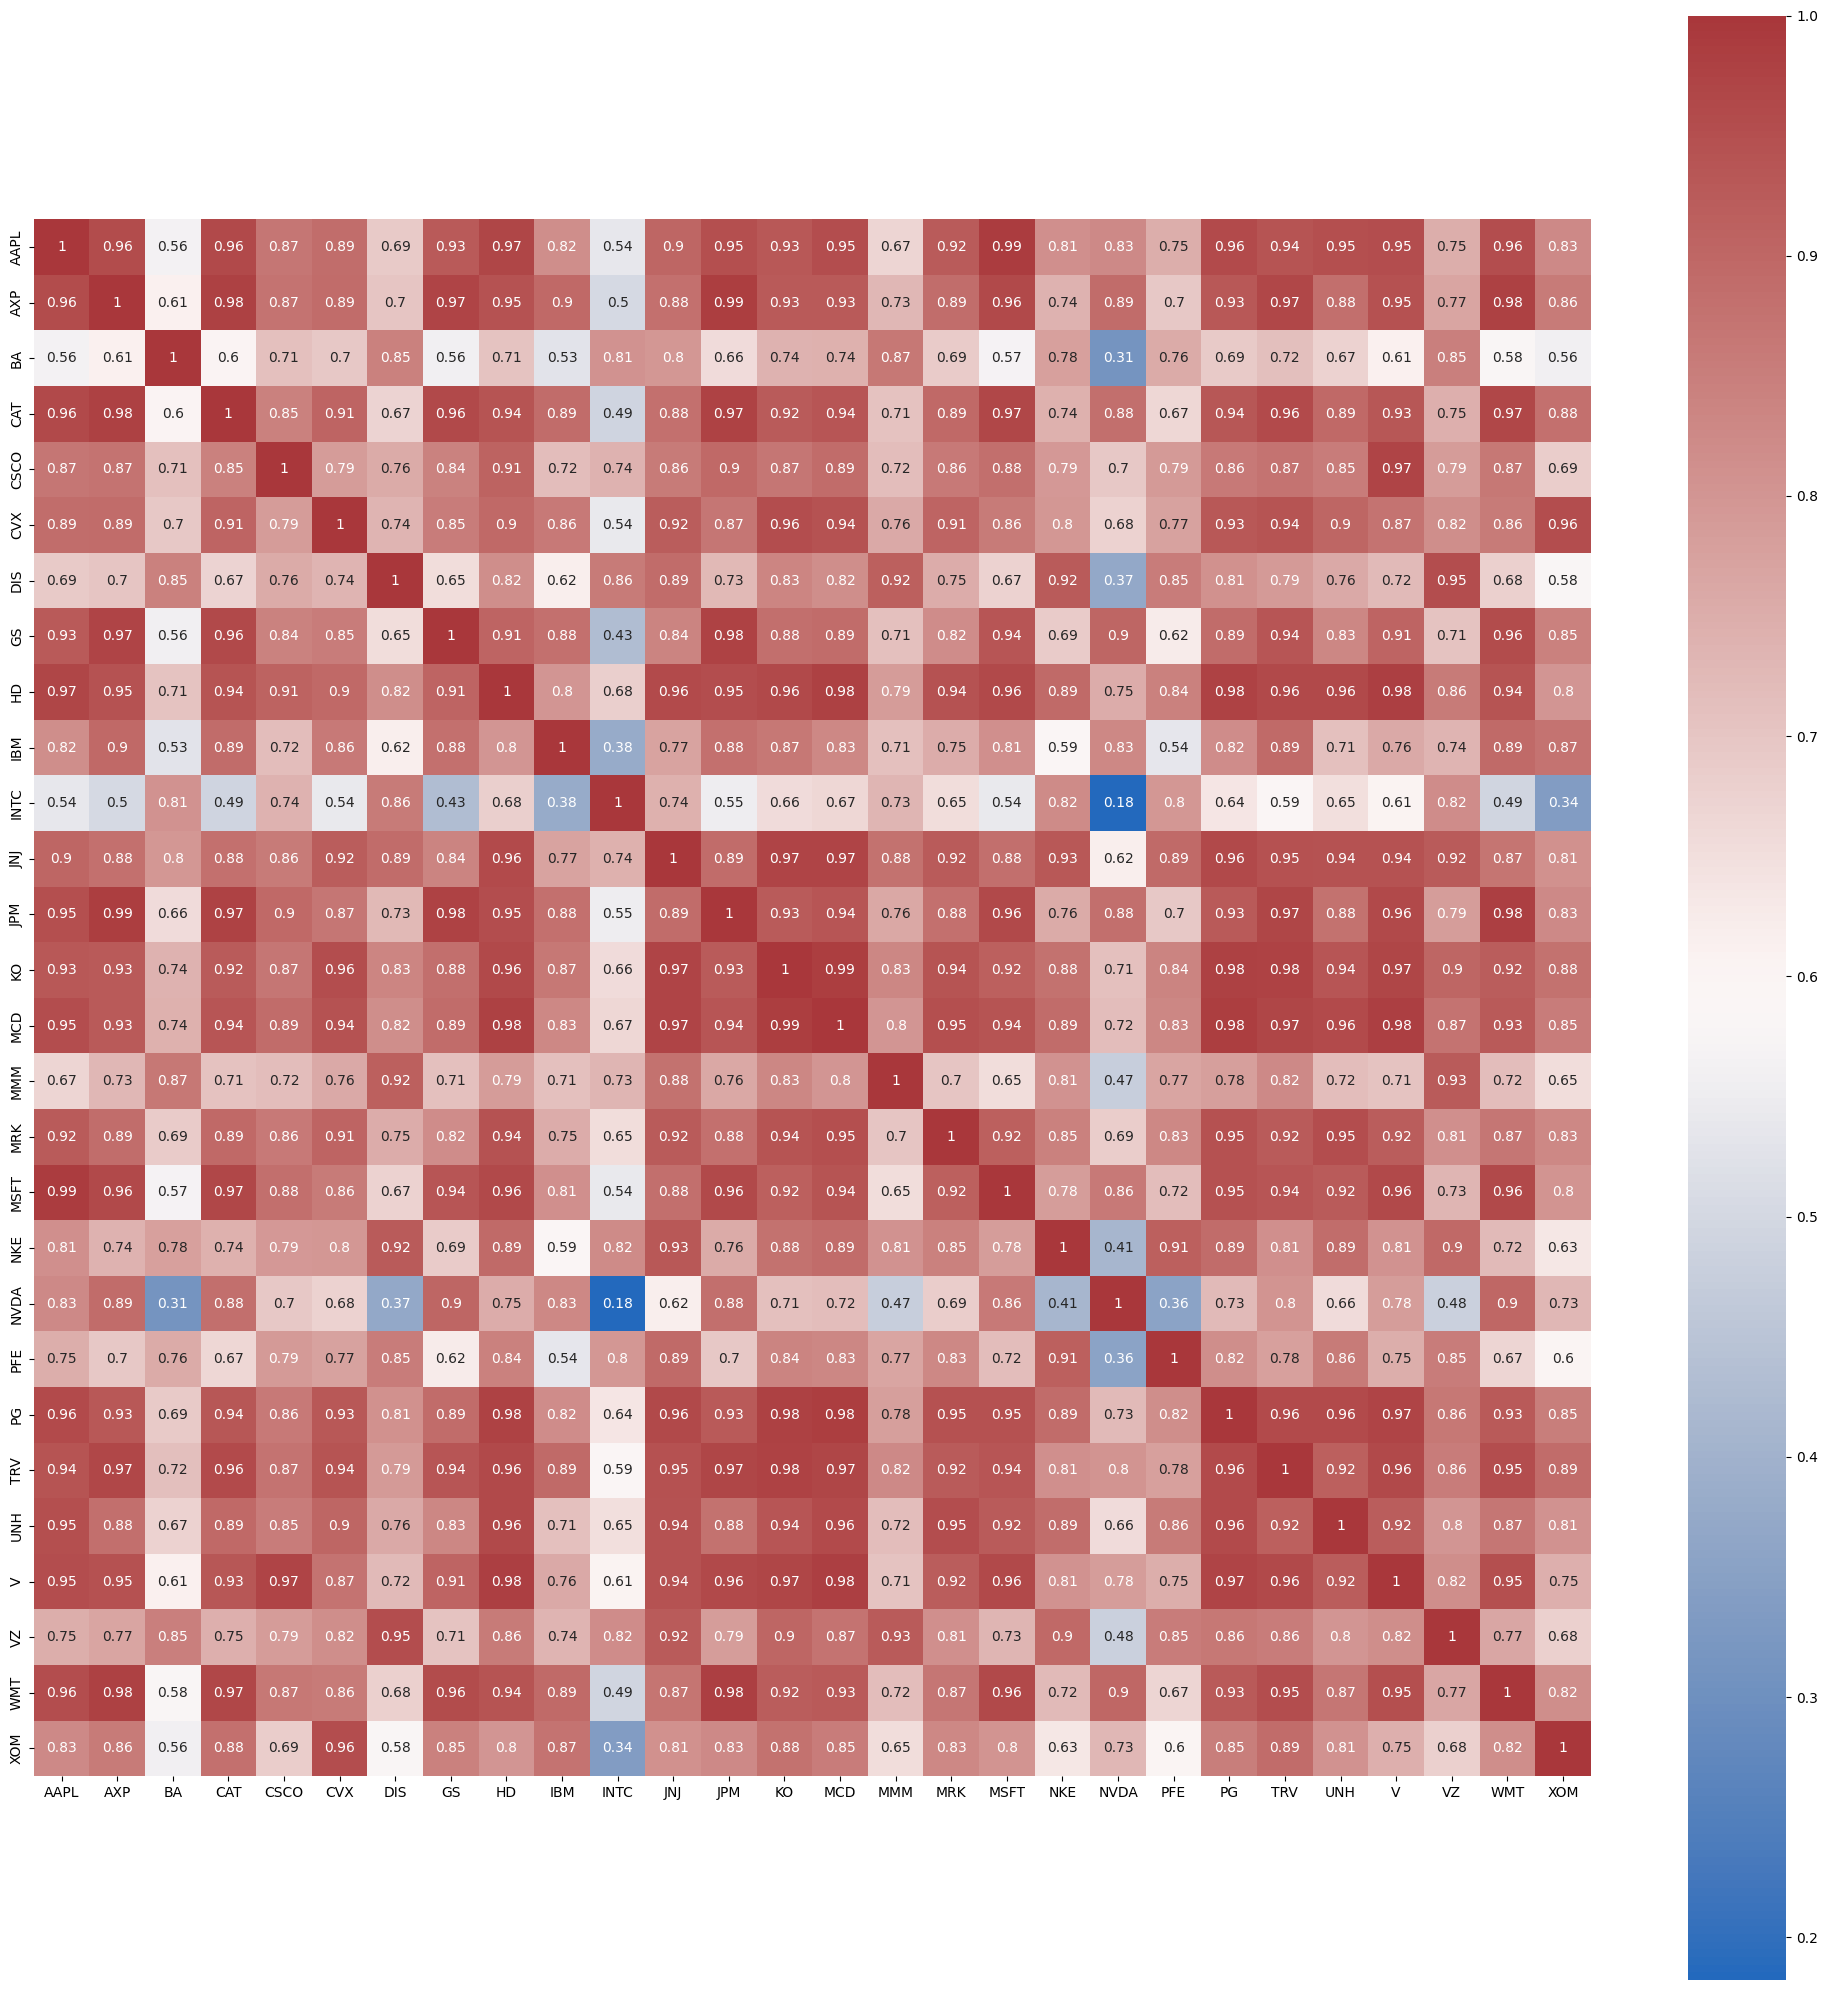

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Cargar los datos (si no lo has hecho) ---
# Asume que tu archivo está en 'inputs/djia_adjusted_closes.csv'
try:
    dataset = pd.read_csv('inputs/djia_adjusted_closes.csv', index_col=0, parse_dates=True)
    print("Datos cargados exitosamente.")
except FileNotFoundError:
    print("Error: No se encontró el archivo 'inputs/djia_adjusted_closes.csv'")
    print("Asegúrate de haber ejecutado el script de descarga primero.")

# --- 2. Calcular la correlación ---
# Usamos el método .corr() en el DataFrame de precios
correlation = dataset.corr()

print("Matriz de correlación calculada.")

# --- 3. Generar el Heatmap ---
# Configuramos el tamaño de la figura para que sea grande y legible
plt.figure(figsize=(15, 20))

# Creamos el heatmap con seaborn
sns.heatmap(
    correlation,        # La matriz de correlación
    vmax=1,             # El valor máximo de la barra de color (1 es correlación perfecta)
    square=True,        # Asegura que cada celda sea un cuadrado
    annot=True,         # Muestra los números (coeficientes de correlación) en cada celda
    cmap='vlag'         # El mapa de color (rojo-blanco-azul) que usa la guía
)

# Ajustamos el layout para que no se corten las etiquetas
plt.tight_layout()

# Mostramos el gráfico
plt.show()

Rojo oscuro (cercano a 1): Significa que dos acciones están altamente correlacionadas. Cuando una sube, la otra casi siempre sube también.

Azul oscuro (cercano a -1): Correlación negativa. Cuando una sube, la otra baja (verás muy pocos de estos).

Blanco (cercano a 0): No hay correlación lineal.

In [14]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 6488 entries, 2000-01-03 to 2025-10-17
Data columns (total 28 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    6488 non-null   float64
 1   AXP     6488 non-null   float64
 2   BA      6488 non-null   float64
 3   CAT     6488 non-null   float64
 4   CSCO    6488 non-null   float64
 5   CVX     6488 non-null   float64
 6   DIS     6488 non-null   float64
 7   GS      6488 non-null   float64
 8   HD      6488 non-null   float64
 9   IBM     6488 non-null   float64
 10  INTC    6488 non-null   float64
 11  JNJ     6488 non-null   float64
 12  JPM     6488 non-null   float64
 13  KO      6488 non-null   float64
 14  MCD     6488 non-null   float64
 15  MMM     6488 non-null   float64
 16  MRK     6488 non-null   float64
 17  MSFT    6488 non-null   float64
 18  NKE     6488 non-null   float64
 19  NVDA    6488 non-null   float64
 20  PFE     6488 non-null   float64
 21  PG      6488 non-nu

In [15]:
# 1. Calcular la proporción de missings por columna
proporcion_missing = dataset.isnull().mean().sort_values(ascending=False)

# Vemos las 5 columnas con más missings
print("Proporción de Missings:")
print(proporcion_missing.head())

# 2. Crear una lista de columnas a eliminar
# (En la guía, el umbral es 0, pero 'V' es el único con muchos missings) [cite: 222]
drop_list = list(proporcion_missing[proporcion_missing > 0.4].index) # Eliminamos si falta más del 40%
print(f"\nColumnas a eliminar: {drop_list}")

# 3. Eliminar esas columnas del DataFrame
dataset = dataset.drop(labels=drop_list, axis=1)
print(f"\nForma de los datos después de eliminar: {dataset.shape}")

Proporción de Missings:
V       0.317972
AAPL    0.000000
BA      0.000000
AXP     0.000000
CSCO    0.000000
dtype: float64

Columnas a eliminar: []

Forma de los datos después de eliminar: (6488, 28)


In [17]:
# 1. Calcular los retornos diarios (variación porcentual)
datareturns = dataset.pct_change(periods=1)

# 2. Ver el resultado
# El primer día (2000-01-03) no tiene un día anterior para comparar.
# Por lo tanto, su retorno es 'NaN' (Not a Number).
print("Datos transformados a retornos (notar el NaN en la primera fila):")
datareturns.head()

# 3. Eliminar la primera fila que contiene 'NaN'
datareturns = datareturns.dropna(how="any")

# ¡LISTO! Ahora tenemos una tabla limpia de retornos diarios.
print("\nDatos de retornos listos para el análisis:")
datareturns.head()

Datos transformados a retornos (notar el NaN en la primera fila):

Datos de retornos listos para el análisis:


,AAPL,AXP,BA,CAT,CSCO,CVX,DIS,GS,HD,IBM,...,NKE,NVDA,PFE,PG,TRV,UNH,V,VZ,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2008-03-20,0.027762,0.094762,0.018380,0.001221,0.012260,0.016119,0.021127,0.078924,0.045454,0.011886,...,0.087983,0.048698,-0.000971,0.023005,0.029735,-0.006470,0.138938,0.028181,0.048247,0.006751
2008-03-24,0.046973,0.031101,0.019920,0.029937,0.035123,0.009614,0.004389,-0.004175,0.042766,0.006169,...,0.026906,0.081534,0.000971,0.008649,-0.002093,0.011042,-0.071795,0.023533,0.007514,0.011177
2008-03-25,0.010392,0.002109,-0.005112,0.008023,0.004290,0.006309,0.001248,0.004192,-0.017089,-0.009155,...,-0.010277,0.014479,0.008248,-0.006145,0.001468,-0.012041,0.058932,-0.001893,-0.010815,-0.008726
2008-03-26,0.028940,-0.045253,0.005270,0.009395,-0.037670,0.004968,-0.009975,-0.023103,-0.020862,-0.008985,...,-0.030716,-0.031989,-0.004331,0.001438,-0.004397,-0.033447,0.011225,-0.020596,-0.002828,0.012441
2008-03-27,-0.033158,-0.011685,-0.027261,-0.004266,-0.024213,-0.006591,-0.011964,-0.041828,-0.013140,-0.011890,...,-0.004376,-0.014235,-0.006283,-0.003303,-0.001893,-0.002932,-0.016417,-0.004981,-0.010019,-0.000696


In [18]:
from sklearn.preprocessing import StandardScaler

# 1. Crear el objeto StandardScaler
scaler = StandardScaler()

# 2. Ajustar el escalador a nuestros datos.
# Esto calcula la media (μ) y la desviación estándar (σ) de cada acción.
scaler.fit(datareturns)

# 3. Transformar (aplicar la fórmula)
rescaled_data_array = scaler.transform(datareturns)

# 4. Convertir el resultado (un array de numpy) de vuelta a un DataFrame
# Es importante mantener las fechas (index) y los tickers (columns)
rescaled_data = pd.DataFrame(rescaled_data_array, 
                            columns=datareturns.columns, 
                            index=datareturns.index)

# ¡LISTO! Los datos están limpios, transformados y escalados.
print("Datos estandarizados (listos para PCA):")
rescaled_data.head()

Datos estandarizados (listos para PCA):


,AAPL,AXP,BA,CAT,CSCO,CVX,DIS,GS,HD,IBM,...,NKE,NVDA,PFE,PG,TRV,UNH,V,VZ,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2008-03-20,1.375219,4.046032,0.763669,0.022683,0.665524,0.850672,1.127579,3.475400,2.696098,0.759844,...,4.505673,1.516812,-0.086470,1.922163,1.658464,-0.350901,7.659661,2.099880,3.653277,0.373858
2008-03-24,2.367228,1.304543,0.829755,1.428146,1.958556,0.497141,0.212870,-0.214656,2.533631,0.379905,...,1.357363,2.580183,0.042591,0.703277,-0.155747,0.495535,-4.034700,1.749274,0.531058,0.632520
2008-03-25,0.478211,0.056076,-0.244289,0.355622,0.214777,0.317497,0.041240,0.156903,-1.083701,-0.638597,...,-0.559326,0.408659,0.526181,-0.552787,0.047226,-0.620204,3.219859,-0.168742,-0.873870,-0.530577
2008-03-26,1.436041,-1.983526,0.201155,0.422737,-2.158243,0.244624,-0.572106,-1.055170,-1.311724,-0.627269,...,-1.612846,-1.096146,-0.309815,0.091058,-0.287091,-1.654874,0.572423,-1.579557,-0.261649,0.706439
2008-03-27,-1.770679,-0.537941,-1.194625,-0.245873,-1.397187,-0.383614,-0.680816,-1.886670,-0.845077,-0.820321,...,-0.255143,-0.521204,-0.439532,-0.311428,-0.144380,-0.179901,-0.961537,-0.401656,-0.812847,-0.061330


In [19]:
# Definir el punto de corte (80% de los datos)
prop_training = int(len(rescaled_data) * 0.8)
print(f"El 80% de los datos equivale a {prop_training} filas.")

# --- Muestras para PCA (Datos Escalares) ---
# Datos de entrenamiento
X_train = rescaled_data[:prop_training]
# Datos de prueba
X_test = rescaled_data[prop_training:]

# --- Muestras para Backtesting (Datos Originales) ---
# Guardamos los retornos *originales* (sin escalar)
X_train_raw = datareturns[:prop_training]
X_test_raw = datareturns[prop_training:]

print(f"\nTotal de días: {len(rescaled_data)}")
print(f"Días de entrenamiento (train): {len(X_train)}")
print(f"Días de prueba (test): {len(X_test)}")

El 80% de los datos equivale a 3539 filas.

Total de días: 4424
Días de entrenamiento (train): 3539
Días de prueba (test): 885


In [21]:
from sklearn.decomposition import PCA

# 1. Crear una instancia del modelo PCA
# Por defecto, crea tantos componentes como variables (en nuestro caso, 27)
pca = PCA()

# 2. Entrenar el modelo con los datos de entrenamiento (escalados)
PrincipalComponent = pca.fit(X_train)
print("Modelo PCA entrenado.")

# 3. Analizar el resultado: Varianza Explicada
# Este atributo nos dice qué porcentaje de la varianza total 
# explica cada componente, en orden de importancia.
varianza_explicada = pca.explained_variance_ratio_

print(f"\nNúmero de componentes encontrados: {len(varianza_explicada)}")

# 4. Ver el hallazgo más importante
print(f"\nEl Componente Principal 1 (PC1) explica el {varianza_explicada[0] * 100:.2f}% de TODA la varianza.")
print(f"El Componente Principal 2 (PC2) explica el {varianza_explicada[1] * 100:.2f}% de la varianza.")
print(f"El Componente Principal 3 (PC3) explica el {varianza_explicada[2] * 100:.2f}% de la varianza.")
print(f"El Componente Principal 3 (PC3) explica el {varianza_explicada[3] * 100:.2f}% de la varianza.")

# Puedes imprimir el array completo si quieres
print("\nVarianza explicada por cada componente:")
print(varianza_explicada)

Modelo PCA entrenado.

Número de componentes encontrados: 28

El Componente Principal 1 (PC1) explica el 49.48% de TODA la varianza.
El Componente Principal 2 (PC2) explica el 5.50% de la varianza.
El Componente Principal 3 (PC3) explica el 4.27% de la varianza.
El Componente Principal 3 (PC3) explica el 3.27% de la varianza.

Varianza explicada por cada componente:
[0.49475652 0.05498891 0.04269324 0.03273238 0.02929849 0.02567343
 0.02157404 0.02097632 0.02002472 0.01894556 0.01820191 0.01695953
 0.0168768  0.01631651 0.01619999 0.01495065 0.01470138 0.01415011
 0.01402732 0.01381315 0.01336769 0.01290257 0.0122014  0.01088979
 0.01006506 0.00988694 0.00787697 0.00494861]


Varianza explicada por los primeros 5 componentes:
0     49.475652
1      5.498891
2      4.269324
3      3.273238
4      2.929849
5      2.567343
6      2.157404
7      2.097632
8      2.002472
9      1.894556
10     1.820191
11     1.695953
12     1.687680
13     1.631651
14     1.619999
dtype: float64

Varianza ACUMULADA por los primeros 5 componentes:
0     49.475652
1     54.974544
2     59.243868
3     62.517106
4     65.446955
5     68.014298
6     70.171702
7     72.269334
8     74.271806
9     76.166362
10    77.986553
11    79.682506
12    81.370186
13    83.001837
14    84.621836
dtype: float64


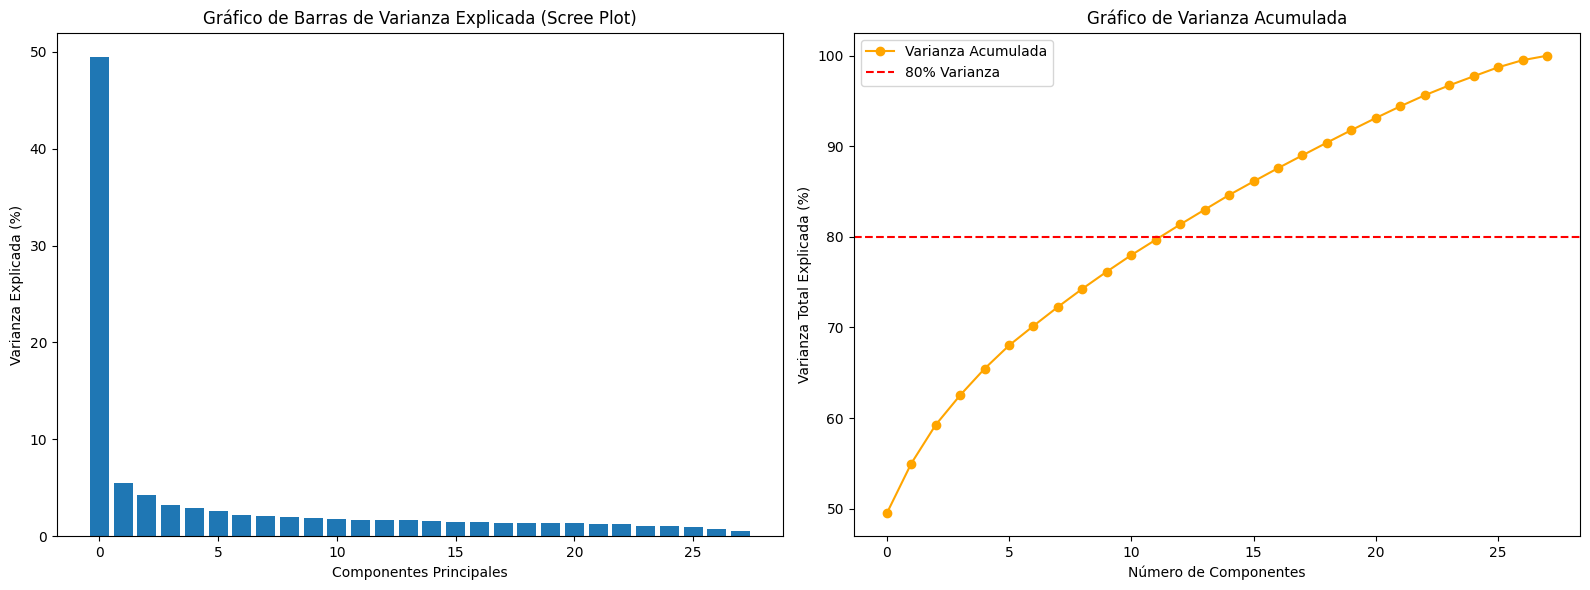

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Crear un DataFrame con la varianza explicada para facilitar el gráfico
# (multiplicamos por 100 para verlo en porcentaje)
varianza_explicada = pd.Series(pca.explained_variance_ratio_ * 100)
varianza_explicada_acumulada = varianza_explicada.cumsum()

print("Varianza explicada por los primeros 5 componentes:")
print(varianza_explicada.head(15))

print("\nVarianza ACUMULADA por los primeros 5 componentes:")
print(varianza_explicada_acumulada.head(15))

# 2. Crear la figura con 2 subplots (uno al lado del otro)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Gráfico 1: Varianza Individual (Scree Plot) ---
ax1.bar(
    varianza_explicada.index, 
    varianza_explicada,
    label='Varianza Individual'
)
ax1.set_title('Gráfico de Barras de Varianza Explicada (Scree Plot)')
ax1.set_xlabel('Componentes Principales')
ax1.set_ylabel('Varianza Explicada (%)')

# --- Gráfico 2: Varianza Acumulada ---
ax2.plot(
    varianza_explicada_acumulada, 
    label='Varianza Acumulada',
    color='orange',
    marker='o'
)
ax2.set_title('Gráfico de Varianza Acumulada')
ax2.set_xlabel('Número de Componentes')
ax2.set_ylabel('Varianza Total Explicada (%)')

# Añadir una línea en el 95% o 80% es común
ax2.axhline(y=80, color='r', linestyle='--', label='80% Varianza')
ax2.legend()

plt.tight_layout()
plt.show()

Cargas (pesos) de las acciones en los primeros 5 Componentes:


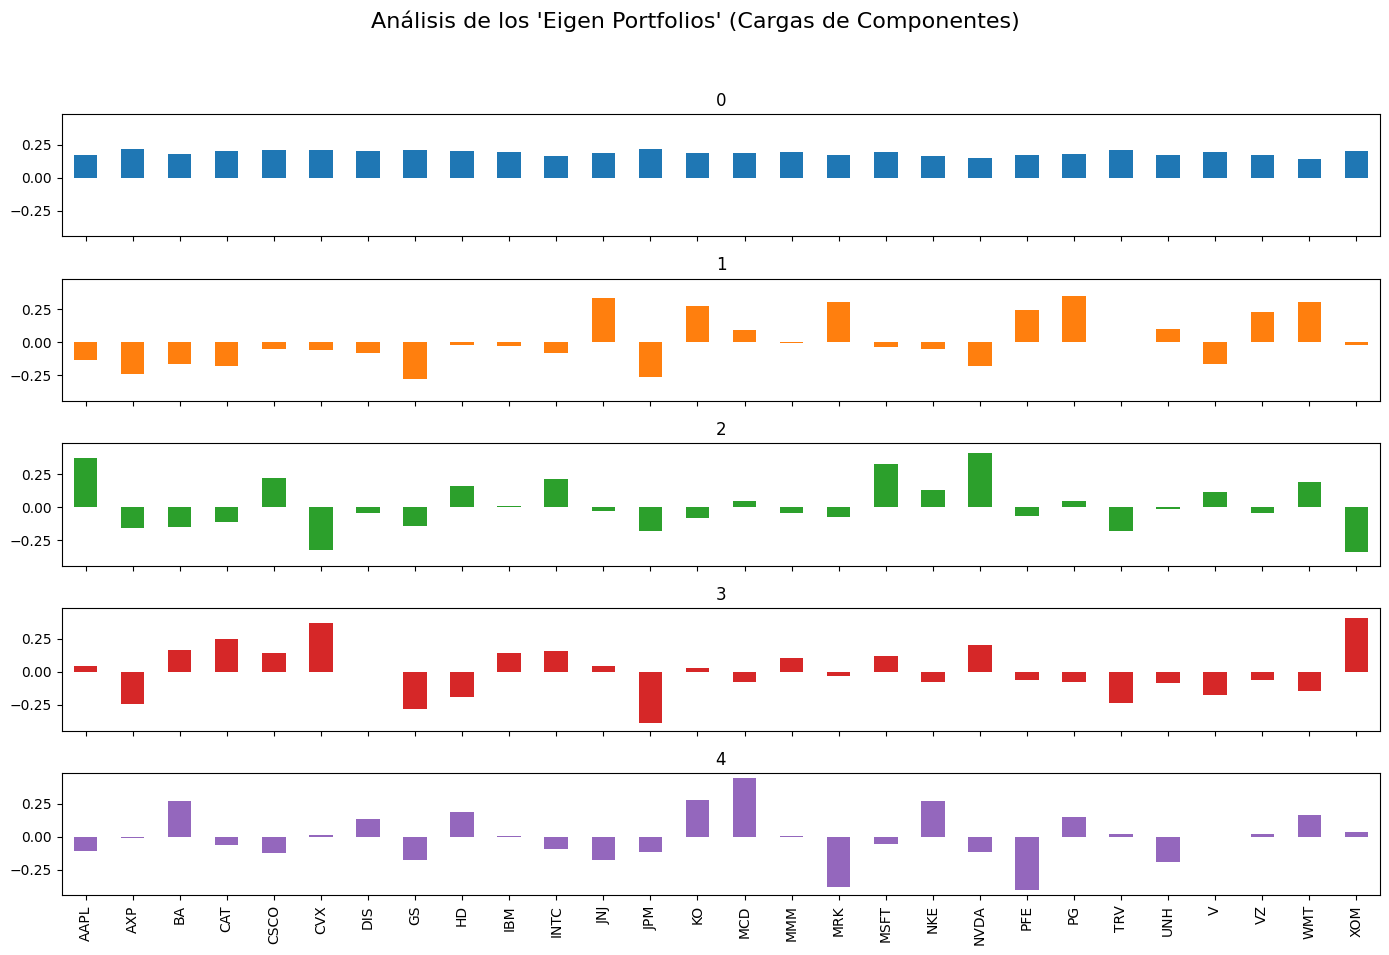

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definir cuántos portafolios (componentes) queremos ver
n_portfolios = 5

# 2. Extraer los pesos (recetas) de los primeros 'n_portfolios'
# pca.components_ es un array donde cada fila es un Eigen Portfolio
# Lo ponemos en un DataFrame para que sea fácil de leer y graficar
# Estas son las "cargas" (loadings) de cada acción en el componente.
component_loadings = pd.DataFrame(pca.components_[:n_portfolios], 
                                columns=X_train.columns)

print("Cargas (pesos) de las acciones en los primeros 5 Componentes:")
component_loadings.head()

# 3. Graficar la "receta" (las cargas) de cada Eigen Portfolio
# Usamos .T (transponer) para que los tickers estén en el eje X
component_loadings.T.plot.bar(
    subplots=True,            # Un gráfico separado para cada portafolio
    layout=(n_portfolios, 1), # Ordenarlos verticalmente
    figsize=(14, 10),         # Tamaño de la figura
    legend=False,             # Quitar la leyenda
    sharey=True               # Compartir el mismo eje Y para comparar
)

plt.suptitle("Análisis de los 'Eigen Portfolios' (Cargas de Componentes)", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Ajustar para el supertítulo
plt.show()

--- RESULTADO DE LA OPTIMIZACIÓN ---
El eigen portfolio #0 tiene el mayor sharpe.
Ret = 16.48%, Volatilidad = 20.39%, Sharpe = 0.81


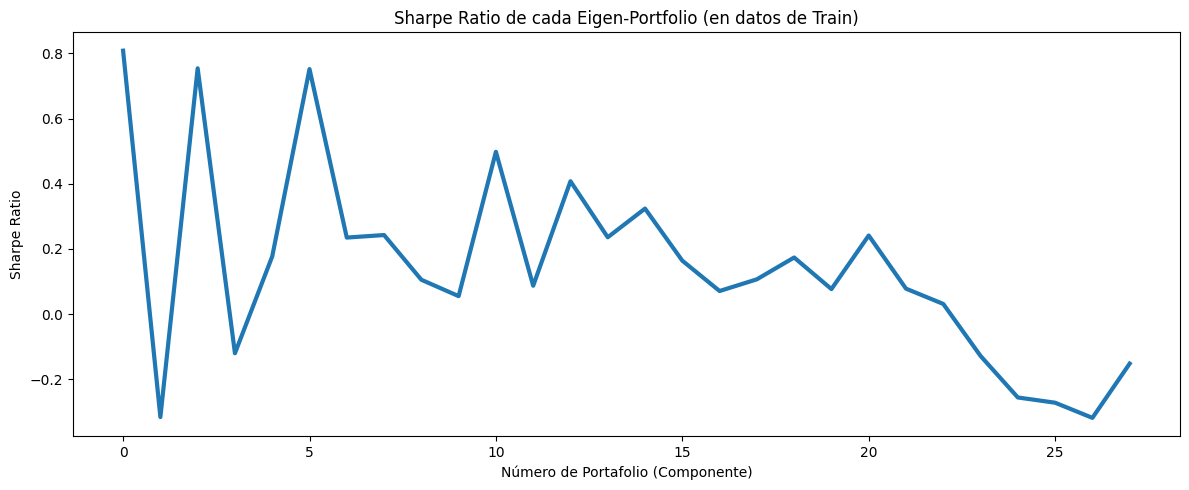

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Función Auxiliar: Calculadora de Sharpe Ratio (ESTABLE) ---
def sharpe_ratio(ts_returns, periods_per_year=252):
    n_years = ts_returns.shape[0] / periods_per_year
    
    # (i) Retorno Anualizado (Forma Aritmética Estable)
    # Simplemente promediamos los retornos diarios y los multiplicamos por 252
    annualized_return = ts_returns.mean() * periods_per_year
    
    # (ii) Volatilidad Anualizada (Esta ya era estable)
    annualized_vol = ts_returns.std() * np.sqrt(periods_per_year)
    
    # (iii) Sharpe Ratio Anualizado
    # Evitamos dividir por cero si la volatilidad es 0
    if annualized_vol == 0:
        annualized_sharpe = 0.0
    else:
        annualized_sharpe = annualized_return / annualized_vol
    
    return annualized_return, annualized_vol, annualized_sharpe

# --- 2. Función Principal: Optimización de Portafolios ---
def portfolio_optimization():
    n_portfolios = len(pca.components_)
    pcs = pca.components_
    
    annualized_ret = np.array([0.] * n_portfolios)
    annualized_vol = np.array([0.] * n_portfolios)
    sharpe_metric = np.array([0.] * n_portfolios)

    for i in range(n_portfolios):
        pc_w = pcs[i] / sum(pcs[i])
        
        eigen_prti_returns = np.dot(X_train_raw.loc[:, X_train.columns], pc_w)
        eigen_prti_returns = pd.Series(eigen_prti_returns.squeeze(), index=X_train_raw.index)
        
        # Calcular el Sharpe Ratio con la función estable
        er, vol, sharpe = sharpe_ratio(eigen_prti_returns)
        
        annualized_ret[i] = er
        annualized_vol[i] = vol
        sharpe_metric[i] = sharpe

    sharpe_metric = np.nan_to_num(sharpe_metric) # Reemplaza NaN (si hubo)
    
    # --- 3. Mostrar Resultados ---
    highest_sharpe = np.argmax(sharpe_metric)

    print('--- RESULTADO DE LA OPTIMIZACIÓN ---')
    print('El eigen portfolio #%d tiene el mayor sharpe.' % highest_sharpe)
    print('Ret = %.2f%%, Volatilidad = %.2f%%, Sharpe = %.2f' % 
        (annualized_ret[highest_sharpe]*100, 
        annualized_vol[highest_sharpe]*100, 
        sharpe_metric[highest_sharpe]))

    # Graficar todos los Sharpe Ratios
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(sharpe_metric, linewidth=3)
    ax.set_title('Sharpe Ratio de cada Eigen-Portfolio (en datos de Train)')
    ax.set_ylabel('Sharpe Ratio')
    ax.set_xlabel('Número de Portafolio (Componente)')
    plt.tight_layout()
    plt.show()

# --- 4. Ejecutar la optimización ---
portfolio_optimization()

In [28]:
# --- 1. Definir funciones auxiliares (de la guía) para obtener los pesos ---

def pc_weights():
    """
    Calcula los pesos de los vectores originales en cada uno de los componentes principales.
    Requiere un modelo PCA entrenado y con nombre 'pca'.
    """
    # pca.components_ tiene las "cargas", pero las normalizamos para que sumen 1
    weights = pd.DataFrame()
    for i in range(len(pca.components_)):
        weights[f"weights_{i}"] = pca.components_[i] / sum(pca.components_[i])
    
    # Devolvemos los pesos transpuestos (cada fila es un portafolio)
    weights = weights.values.T
    return weights

def get_weights(weights, tickers):
    """
    Convierte un array de pesos en un DataFrame bonito y ordenado.
    """
    portfolio = pd.DataFrame(data={'weights': weights.squeeze() * 100}, 
                            index=tickers)
    portfolio.sort_values(by=['weights'], ascending=False, inplace=True)
    return portfolio

# --- 2. Extraer y mostrar la receta ganadora (#5) ---

stock_tickers = rescaled_data.columns.values

# Obtener TODAS las recetas (del 0 al 26)
all_weights = pc_weights()

# Seleccionar solo la receta ganadora (la fila 5)
epf_5_weights = all_weights[5]

# Convertir la receta en una tabla legible
pesos_portfolio_5 = get_weights(weights=epf_5_weights, tickers=stock_tickers)

print("--- 'Receta' del Eigen Portfolio #5 (El Ganador) ---")
print(pesos_portfolio_5)

--- 'Receta' del Eigen Portfolio #5 (El Ganador) ---
          weights
UNH   1028.413719
MCD    641.379682
MRK    371.434699
BA     361.545870
AAPL   295.932883
V      246.628210
CVX    186.956458
PFE    168.212850
TRV    153.411338
NVDA   125.705428
NKE    109.876868
KO      76.386653
MSFT    66.972842
HD      57.489059
JNJ     46.528413
XOM     20.703243
AXP      1.973331
DIS    -17.843842
INTC  -151.220278
GS    -221.326340
MMM   -287.510198
JPM   -356.049303
PG    -372.273583
CAT   -390.473388
IBM   -398.079240
CSCO  -452.253998
WMT   -478.510836
VZ    -734.010540


--- RESULTADO DEL BACKTESTING (Datos de Prueba) ---
Eigen-Portfolio Ganador: Ret = -382.78%, Vol = 497.46%, Sharpe = -0.77


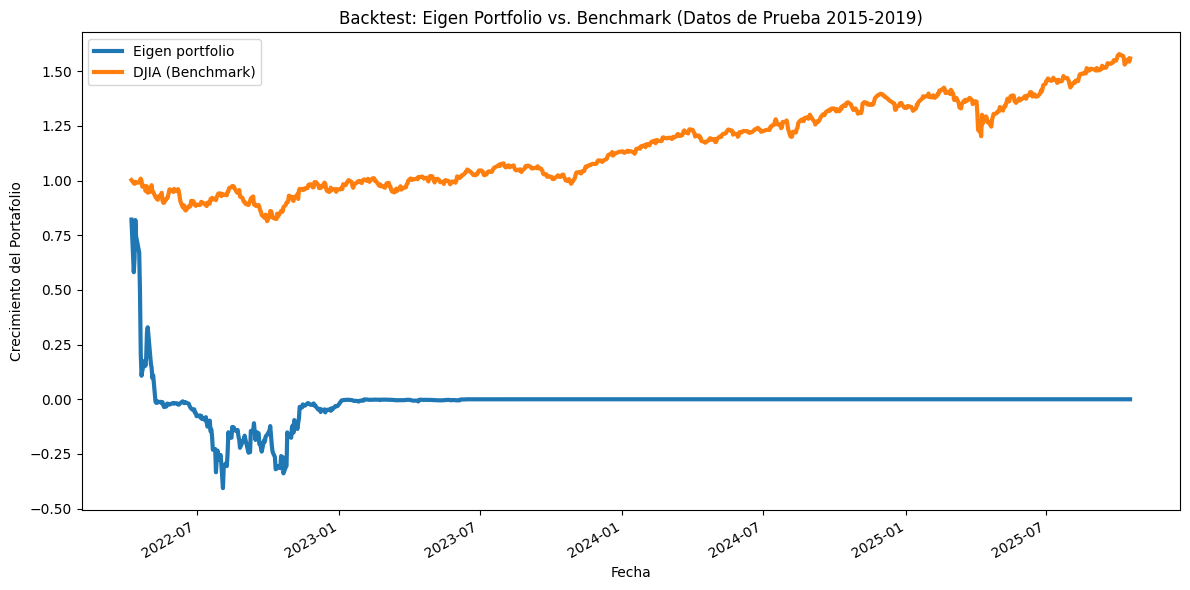

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. Definir la función de Backtesting ---
# (Asegúrate de haber ejecutado la celda con la función sharpe_ratio() antes)
def backtest(eigen_weights, eigen_returns_test, benchmark_returns_test):
    """
    Compara el retorno acumulado de un Eigen Portfolio contra un benchmark.
    """
    
    # 1. Calcula los retornos de nuestra estrategia
    # Multiplica los pesos por los retornos diarios de prueba
    eigen_portfolio_returns = np.dot(eigen_returns_test, eigen_weights)
    eigen_portfolio_returns = pd.Series(eigen_portfolio_returns.squeeze(), index=eigen_returns_test.index)
    
    # 2. Calcula las métricas de nuestra estrategia en los datos de prueba
    returns, vol, sharpe = sharpe_ratio(eigen_portfolio_returns)
    print('--- RESULTADO DEL BACKTESTING (Datos de Prueba) ---')
    print('Eigen-Portfolio Ganador: Ret = %.2f%%, Vol = %.2f%%, Sharpe = %.2f' % 
          (returns * 100, vol * 100, sharpe))
    
    # 3. Prepara el DataFrame para graficar
    df_plot = pd.DataFrame({
        'Eigen portfolio': eigen_portfolio_returns, 
        'DJIA (Benchmark)': benchmark_returns_test
    }, index=eigen_returns_test.index)
    
    # 4. Grafica el retorno acumulado (usa np.cumprod para ver el crecimiento)
    (np.cumprod(df_plot + 1)).plot(figsize=(12, 6), linewidth=3)
    plt.title('Backtest: Eigen Portfolio vs. Benchmark (Datos de Prueba 2015-2019)')
    plt.ylabel('Crecimiento del Portafolio')
    plt.xlabel('Fecha')
    plt.tight_layout()
    plt.show()

# --- 2. Preparar los datos para el Backtest ---

# Los tickers (asegúrate de que esta variable existe)
stock_tickers = rescaled_data.columns.values

# Los pesos de nuestra receta ganadora (de la celda anterior)
# epf_5_weights = all_weights[5]

# Los retornos de prueba (los datos que el modelo no ha visto)
eigen_returns_test = X_test_raw.loc[:, stock_tickers]

# El benchmark: un portafolio simple con pesos iguales
num_tickers = len(stock_tickers)
benchmark_returns_test = (X_test_raw.loc[:, stock_tickers] * (1 / num_tickers)).sum(axis=1)

# --- 3. Ejecutar la prueba de fuego ---
backtest(
    eigen_weights=epf_5_weights, 
    eigen_returns_test=eigen_returns_test,
    benchmark_returns_test=benchmark_returns_test
)